# SONAR Case Study: Detecting Mines vs. Rocks with an Artificial Neural Network

**Course assignment – Neural Networks / Deep Learning**
**Library:** TensorFlow / Keras (high-level API) · scikit-learn (preprocessing, splitting, metrics)

---

## Contents
1. Business objective & problem statement
2. Data exploration and preprocessing
3. Baseline ANN (default hyperparameters)
4. Hyperparameter tuning (structured grid search with cross-validation)
5. Evaluation – metrics and baseline vs. tuned comparison
6. Discussion & conclusions

---

## 1. Business Objective & Problem Statement

**Goal:** build an intelligent system that automatically decides whether an underwater sonar return was reflected by a **metallic mine** (dangerous) or by a harmless **rock**. This matters for maritime safety, naval mine clearance and resource exploration.

**Data:** 208 sonar returns (111 mines, 97 rocks). Each return is described by **60 numeric features** – the signal energy (0.0 – 1.0) in 60 frequency bands of a frequency-modulated chirp. The target is `M` (mine) or `R` (rock).

**Task:** train a neural network that learns the difference in signal patterns, tune its hyperparameters systematically, and evaluate it with accuracy, precision, recall and F1-score.

> **Which error is worse?** Missing a real mine (predicting *Rock* when it is a *Mine*) is far more dangerous than a false alarm. We therefore treat **Mine as the positive class** and pay particular attention to **recall** on mines, in addition to overall accuracy.

## 2. Data Exploration and Preprocessing
### 2.1 Imports and reproducibility settings

In [1]:
import os, warnings, itertools, time, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"          # keep TensorFlow logs quiet
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
def set_seed(seed=SEED):
    """Fix every random number generator so that results are reproducible."""
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)

set_seed()
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1792669308.621059    1439 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792669310.026718    1439 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


### 2.2 Load the data and take a first look

In [2]:
df = pd.read_csv("sonardataset.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (208, 61)


,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_52,x_53,x_54,x_55,x_56,x_57,x_58,x_59,x_60,Y
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [3]:
# Key facts requested by the assignment: samples, features, classes
n_samples  = df.shape[0]
feature_cols = [c for c in df.columns if c != "Y"]
n_features = len(feature_cols)
classes = df["Y"].unique()

print(f"Number of samples : {n_samples}")
print(f"Number of features: {n_features}  ({feature_cols[0]} ... {feature_cols[-1]})")
print(f"Number of classes : {len(classes)}  -> {sorted(classes)}")
print("\nClass counts:\n" + df["Y"].value_counts().to_string())
print("\nClass share (%):\n" + (df["Y"].value_counts(normalize=True)*100).round(1).to_string())

Number of samples : 208
Number of features: 60  (x_1 ... x_60)
Number of classes : 2  -> ['M', 'R']

Class counts:
Y
M    111
R     97

Class share (%):
Y
M    53.4
R    46.6


In [4]:
# Data types, missing values, duplicates and value range
print("All feature columns numeric:", all(pd.api.types.is_numeric_dtype(df[c]) for c in feature_cols))
print("Missing values (total)     :", int(df.isna().sum().sum()))
print("Duplicated rows            :", int(df.duplicated().sum()))
print(f"Feature value range        : {df[feature_cols].min().min():.4f} to {df[feature_cols].max().max():.4f}")
df[feature_cols].describe().T.round(3).head(10)

All feature columns numeric: True
Missing values (total)     : 0
Duplicated rows            : 0
Feature value range        : 0.0000 to 1.0000


,count,mean,std,min,25%,50%,75%,max
x_1,208.0,0.029,0.023,0.002,0.013,0.023,0.036,0.137
x_2,208.0,0.038,0.033,0.001,0.016,0.031,0.048,0.234
x_3,208.0,0.044,0.038,0.002,0.019,0.034,0.058,0.306
x_4,208.0,0.054,0.047,0.006,0.024,0.044,0.064,0.426
x_5,208.0,0.075,0.056,0.007,0.038,0.062,0.100,0.401
x_6,208.0,0.105,0.059,0.010,0.067,0.092,0.134,0.382
x_7,208.0,0.122,0.062,0.003,0.081,0.107,0.154,0.373
x_8,208.0,0.135,0.085,0.006,0.080,0.112,0.170,0.459
x_9,208.0,0.178,0.118,0.008,0.097,0.152,0.233,0.683
x_10,208.0,0.208,0.134,0.011,0.111,0.182,0.269,0.711


**Observations**
- 208 samples × 60 features with two classes, matching the dataset description. The classes are only mildly imbalanced (53 % mines / 47 % rocks), so accuracy is meaningful, but we still use **stratified** splits to keep this ratio everywhere.
- There are no missing values or duplicate rows, and all features already lie in [0, 1]. We nevertheless include a missing-value handling step (median imputation) in the pipeline so that the workflow stays robust if new data arrive with gaps.

### 2.3 Visual exploration

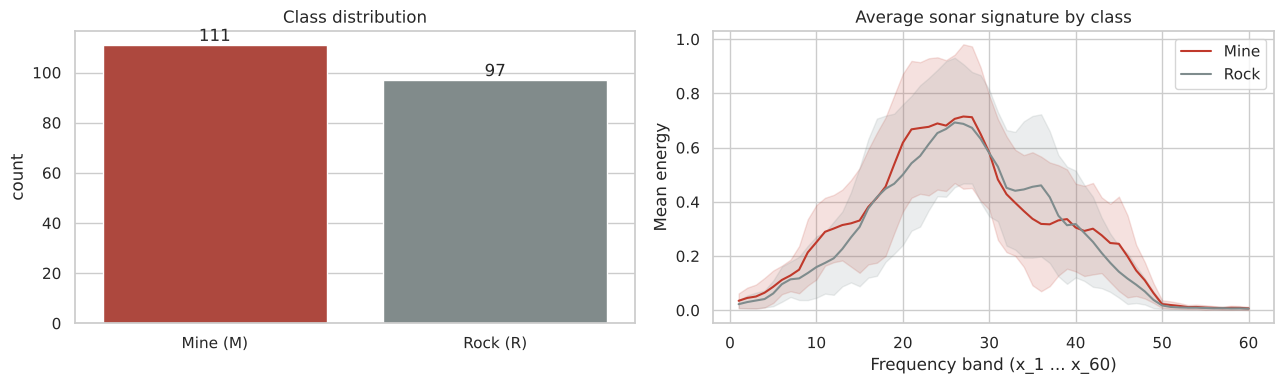

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# (a) class balance
order = ["M", "R"]
sns.countplot(data=df, x="Y", order=order, palette=["#c0392b", "#7f8c8d"], ax=axes[0])
axes[0].set_xticklabels(["Mine (M)", "Rock (R)"]); axes[0].set_xlabel(""); axes[0].set_title("Class distribution")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

# (b) mean spectral profile per class (+/- 1 std)
for lab, colr, name in [("M", "#c0392b", "Mine"), ("R", "#7f8c8d", "Rock")]:
    sub = df.loc[df.Y == lab, feature_cols]
    m, s = sub.mean().values, sub.std().values
    axes[1].plot(range(1, 61), m, color=colr, label=name)
    axes[1].fill_between(range(1, 61), m-s, m+s, color=colr, alpha=0.15)
axes[1].set_xlabel("Frequency band (x_1 ... x_60)"); axes[1].set_ylabel("Mean energy")
axes[1].set_title("Average sonar signature by class"); axes[1].legend()
plt.tight_layout(); plt.show()


The average signatures of mines and rocks are similar in overall shape (energy peaks around bands 20–30 and vanishes beyond band ≈ 50). Mines have somewhat more energy in bands ≈ 10–25 and rocks around bands ≈ 33–38, but the ±1 std bands overlap heavily – the classes are *not* separable by any single feature, which motivates a multivariate, non-linear model such as an ANN.


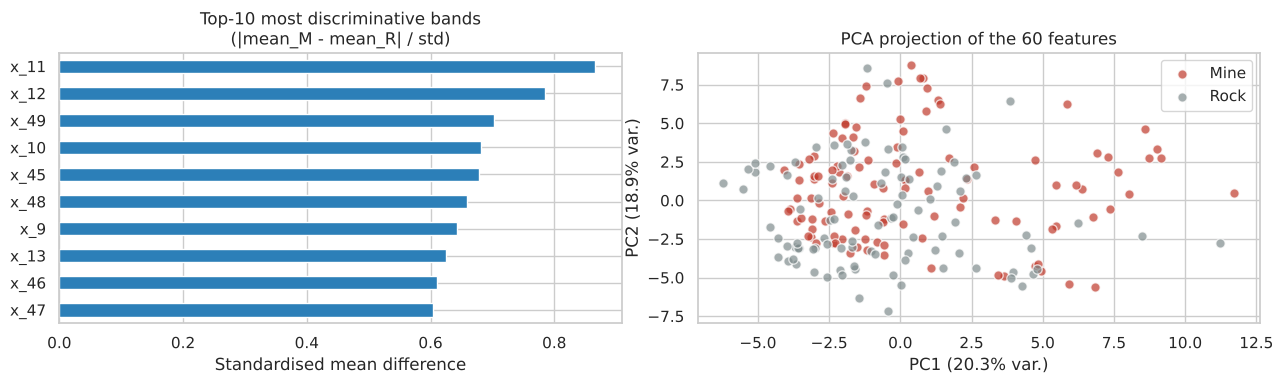

In [6]:
# Which features separate the classes best? (absolute difference of class means, in units of pooled std)
m_mean, r_mean = df[df.Y=="M"][feature_cols].mean(), df[df.Y=="R"][feature_cols].mean()
effect = ((m_mean - r_mean).abs() / df[feature_cols].std()).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
effect.head(10).iloc[::-1].plot.barh(ax=axes[0], color="#2c7fb8")
axes[0].set_title("Top-10 most discriminative bands\n(|mean_M - mean_R| / std)"); axes[0].set_xlabel("Standardised mean difference")

# 2-D PCA projection to see how separable the classes are
Xs = StandardScaler().fit_transform(df[feature_cols])
pca = PCA(n_components=2, random_state=SEED).fit(Xs)
Z = pca.transform(Xs)
for lab, colr, name in [("M", "#c0392b", "Mine"), ("R", "#7f8c8d", "Rock")]:
    idx = (df.Y == lab).values
    axes[1].scatter(Z[idx, 0], Z[idx, 1], c=colr, alpha=0.7, label=name, edgecolor="white", s=45)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var.)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var.)")
axes[1].set_title("PCA projection of the 60 features"); axes[1].legend()
plt.tight_layout(); plt.show()

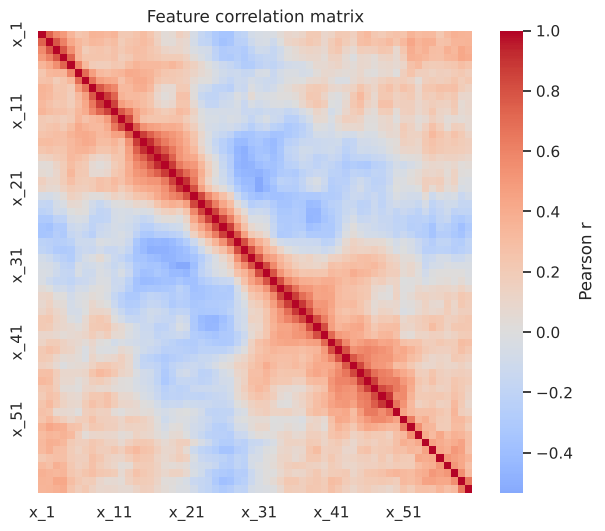

In [7]:
# Correlation between neighbouring frequency bands (the features are strongly inter-correlated)
plt.figure(figsize=(7, 6))
sns.heatmap(df[feature_cols].corr(), cmap="coolwarm", center=0, xticklabels=10, yticklabels=10, cbar_kws={"label": "Pearson r"})
plt.title("Feature correlation matrix"); plt.show()


**Observations**
- Neighbouring frequency bands are positively correlated (the red band along the diagonal), and there are also negative correlations between distant bands (blue blocks, e.g. bands ≈ 10–20 vs. ≈ 22–35). The 60 inputs therefore carry a lot of redundant information. With only 208 samples this makes **over-fitting** a real risk, particularly for large networks.
- The most discriminative single bands (x_11, x_12, x_49, x_10, x_45 …) differ by less than one standard deviation between classes, and the PCA plot shows only partial class separation, so a model has to combine many bands to classify well.


### 2.4 Preprocessing

Steps performed:
1. **Encode the target:** `R → 0`, `M → 1` (Mine is the *positive* class).
2. **Stratified train/test split (80 / 20)** *before* any scaling, so that no information from the test set leaks into preprocessing.
3. **Missing values:** median imputation (fitted on training data only; a no-op here because there are no missing values).
4. **Normalisation:** `StandardScaler` (zero mean, unit variance per feature) fitted **on the training set only** and then applied to the test set. Neural networks train faster and more stably on standardised inputs.

In [8]:
# 1) Encode target: Rock = 0, Mine = 1
y = (df["Y"] == "M").astype("int32").values
X = df[feature_cols].values.astype("float32")

# 2) Stratified 80/20 split (stratify keeps the M/R ratio equal in both sets)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print(f"Train: {X_train_raw.shape}  | mines = {y_train.mean():.1%}")
print(f"Test : {X_test_raw.shape}   | mines = {y_test.mean():.1%}")

Train: (166, 60)  | mines = 53.6%
Test : (42, 60)   | mines = 52.4%


In [9]:
# 3) + 4) Imputation and scaling, fitted on the TRAINING data only
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

preprocessor = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
X_train = preprocessor.fit_transform(X_train_raw).astype("float32")
X_test  = preprocessor.transform(X_test_raw).astype("float32")

print("Train mean (first 5 features):", X_train[:, :5].mean(axis=0).round(3))
print("Train std  (first 5 features):", X_train[:, :5].std(axis=0).round(3))
print("Any NaN left? ", bool(np.isnan(X_train).any() or np.isnan(X_test).any()))

Train mean (first 5 features): [ 0.  0. -0.  0. -0.]
Train std  (first 5 features): [1. 1. 1. 1. 1.]
Any NaN left?  False


## 3. Model Implementation – Baseline ANN

Helper functions below build, train and evaluate Keras models. Using a single `build_ann` function lets the baseline and every grid-search candidate be created in exactly the same way, so differences in performance are due only to the hyperparameters.

**Baseline ("default") configuration:** one hidden layer with 16 ReLU neurons, Adam optimiser with Keras' default learning rate (0.001), batch size 16, 100 epochs, sigmoid output unit with binary cross-entropy loss.

In [10]:
def build_ann(n_inputs, n_hidden_layers=1, n_neurons=16, activation="relu", learning_rate=1e-3):
    """Build and compile a fully connected binary-classification ANN.

    Parameters
    ----------
    n_hidden_layers : number of hidden Dense layers
    n_neurons       : neurons in every hidden layer
    activation      : hidden-layer activation ('relu', 'tanh', ...)
    learning_rate   : learning rate of the Adam optimiser
    """
    model = keras.Sequential([layers.Input(shape=(n_inputs,))])
    for _ in range(n_hidden_layers):
        model.add(layers.Dense(n_neurons, activation=activation))
    model.add(layers.Dense(1, activation="sigmoid"))          # P(Mine)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model


def compute_metrics(y_true, y_pred, y_prob=None):
    """Accuracy, precision, recall, F1 (positive class = Mine) and optionally ROC-AUC."""
    out = {"Accuracy": accuracy_score(y_true, y_pred),
           "Precision": precision_score(y_true, y_pred, zero_division=0),
           "Recall": recall_score(y_true, y_pred, zero_division=0),
           "F1-score": f1_score(y_true, y_pred, zero_division=0)}
    if y_prob is not None:
        out["ROC-AUC"] = roc_auc_score(y_true, y_prob)
    return out

In [11]:
EPOCHS, BATCH = 100, 16

set_seed()
baseline = build_ann(X_train.shape[1], n_hidden_layers=1, n_neurons=16, activation="relu", learning_rate=1e-3)
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

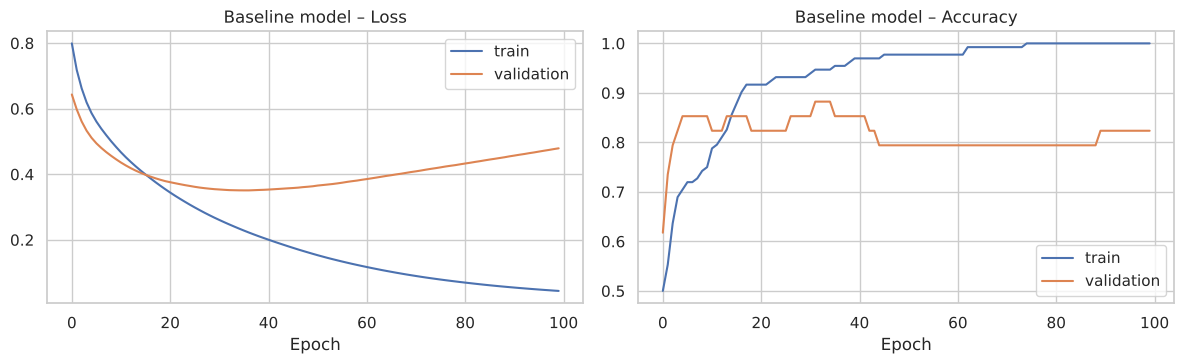

In [12]:
# Train the baseline. 20% of the TRAINING data is held out as validation only to draw learning curves;
# the test set is not touched during training.
set_seed()
hist_base = baseline.fit(X_train, y_train, validation_split=0.2, epochs=EPOCHS,
                         batch_size=BATCH, verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, key, title in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
    ax.plot(hist_base.history[key], label="train")
    ax.plot(hist_base.history["val_" + key], label="validation")
    ax.set_title(f"Baseline model – {title}"); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()


The training loss keeps falling towards zero and training accuracy reaches 100 %, while the validation loss is lowest around epoch 35 and then rises – a classic sign of **over-fitting** on a small data set. We keep this baseline as the reference point for measuring what tuning achieves.

Next we use the baseline to predict on the **test set**. The final baseline that is evaluated is re-trained on the *full* training set (no validation hold-out) so that it is comparable to the tuned model later.


In [13]:
# Final baseline: train on the complete training set, then predict on the test set
set_seed()
baseline = build_ann(X_train.shape[1], 1, 16, "relu", 1e-3)
baseline.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH, verbose=0)

p_base = baseline.predict(X_test, verbose=0).ravel()      # predicted probability of "Mine"
yhat_base = (p_base >= 0.5).astype(int)                    # threshold 0.5 -> class label

res_base = compute_metrics(y_test, yhat_base, p_base)
print("Baseline test-set performance")
print(pd.Series(res_base).round(4).to_string())

Baseline test-set performance
Accuracy     0.9048
Precision    0.8462
Recall       1.0000
F1-score     0.9167
ROC-AUC      0.9591


## 4. Hyperparameter Tuning

### 4.1 Methodology

| Aspect | Choice |
|---|---|
| **Search strategy** | **Exhaustive grid search** over the full Cartesian product of the grid below (a small, fully enumerable space, so no random search is needed and every combination is documented). |
| **Hyper-parameters** | number of hidden layers, neurons per layer, activation function, learning rate |
| **Validation scheme** | **5-fold stratified cross-validation on the training set only** – the test set stays untouched until the final evaluation, preventing selection bias. |
| **Scaling inside CV** | The scaler is re-fitted on each CV-training fold so the validation fold never leaks into preprocessing. |
| **Selection metric** | Mean CV **accuracy** (ties broken by mean CV F1, then lower standard deviation). F1 and recall are also recorded. |
| **Fixed settings** | Adam optimiser, batch size 16, 100 epochs, binary cross-entropy, same seed for every run. |

With only 208 samples a single validation split would be very noisy; averaging over 5 folds gives a more reliable ranking of configurations.

In [14]:
param_grid = {
    "n_hidden_layers": [1, 2, 3],
    "n_neurons":       [8, 32, 64],
    "activation":      ["relu", "tanh"],
    "learning_rate":   [0.01, 0.001],
}
combos = [dict(zip(param_grid, v)) for v in itertools.product(*param_grid.values())]
print(f"{len(combos)} hyper-parameter combinations x 5 folds = {len(combos)*5} model fits")

36 hyper-parameter combinations x 5 folds = 180 model fits


In [15]:
def cross_validate(params, X_tr_raw, y_tr, n_splits=5, epochs=EPOCHS, batch_size=BATCH):
    """Stratified k-fold CV for one hyper-parameter setting; returns mean/std of metrics."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    accs, f1s, recs = [], [], []
    for tr_idx, va_idx in skf.split(X_tr_raw, y_tr):
        scaler = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_tr_raw[tr_idx])
        Xa = scaler.transform(X_tr_raw[tr_idx]).astype("float32")
        Xb = scaler.transform(X_tr_raw[va_idx]).astype("float32")
        keras.backend.clear_session(); set_seed()
        m = build_ann(Xa.shape[1], **params)
        m.fit(Xa, y_tr[tr_idx], epochs=epochs, batch_size=batch_size, verbose=0)
        pred = (m.predict(Xb, verbose=0).ravel() >= 0.5).astype(int)
        accs.append(accuracy_score(y_tr[va_idx], pred))
        f1s.append(f1_score(y_tr[va_idx], pred, zero_division=0))
        recs.append(recall_score(y_tr[va_idx], pred, zero_division=0))
    return {"cv_acc": np.mean(accs), "cv_acc_std": np.std(accs),
            "cv_f1": np.mean(f1s), "cv_recall": np.mean(recs)}

In [16]:
# Run the grid search (takes a few minutes on CPU)
t0 = time.time()
records = []
for i, params in enumerate(combos, 1):
    records.append({**params, **cross_validate(params, X_train_raw, y_train)})
    if i % 6 == 0 or i == len(combos):
        print(f"  {i:>2}/{len(combos)} combinations done  ({time.time()-t0:.0f}s)")

grid_results = (pd.DataFrame(records)
                .sort_values(["cv_acc", "cv_f1", "cv_acc_std"], ascending=[False, False, True])
                .reset_index(drop=True))
grid_results.index += 1
print(f"\nGrid search finished in {time.time()-t0:.0f}s")

   6/36 combinations done  (223s)


  12/36 combinations done  (441s)


  18/36 combinations done  (679s)


  24/36 combinations done  (936s)


  30/36 combinations done  (1202s)


  36/36 combinations done  (1481s)

Grid search finished in 1481s


### 4.2 Grid-search results

In [17]:
print("Top 10 configurations (ranked by mean 5-fold CV accuracy on the training set):")
grid_results.head(10).round(4)

Top 10 configurations (ranked by mean 5-fold CV accuracy on the training set):


,n_hidden_layers,n_neurons,activation,learning_rate,cv_acc,cv_acc_std,cv_f1,cv_recall
1,3,32,relu,0.010,0.8380,0.0871,0.8513,0.8529
2,1,32,tanh,0.010,0.8257,0.0572,0.8405,0.8634
3,2,8,relu,0.001,0.8198,0.0550,0.8351,0.8529
4,2,64,tanh,0.010,0.8196,0.0409,0.8329,0.8418
5,1,64,relu,0.010,0.8196,0.0527,0.8285,0.8190
6,3,64,relu,0.010,0.8139,0.0750,0.8297,0.8301
7,2,32,tanh,0.001,0.8137,0.0627,0.8300,0.8523
8,2,32,relu,0.010,0.8137,0.0952,0.8311,0.8412
9,3,64,relu,0.001,0.8134,0.0748,0.8290,0.8301
10,2,8,tanh,0.001,0.8077,0.0540,0.8273,0.8529


In [18]:
best_params = {k: grid_results.loc[1, k] for k in param_grid}
best_params = {k: (int(v) if k in ("n_hidden_layers", "n_neurons") else (float(v) if k == "learning_rate" else v))
               for k, v in best_params.items()}
print("Best hyper-parameters:", best_params)
print(f"Best CV accuracy     : {grid_results.loc[1,'cv_acc']:.4f} (+/- {grid_results.loc[1,'cv_acc_std']:.4f})")
print("\nWorst 5 configurations:")
grid_results.tail(5).round(4)

Best hyper-parameters: {'n_hidden_layers': 3, 'n_neurons': 32, 'activation': 'relu', 'learning_rate': 0.01}
Best CV accuracy     : 0.8380 (+/- 0.0871)

Worst 5 configurations:


,n_hidden_layers,n_neurons,activation,learning_rate,cv_acc,cv_acc_std,cv_f1,cv_recall
32,1,64,relu,0.001,0.7895,0.0559,0.8051,0.8078
33,1,8,relu,0.001,0.7775,0.0763,0.8013,0.8307
34,3,8,tanh,0.010,0.7656,0.0675,0.7835,0.7967
35,3,8,relu,0.010,0.7412,0.0550,0.7791,0.8425
36,3,8,relu,0.001,0.7226,0.0496,0.7725,0.8863


### 4.3 Effect of each hyper-parameter

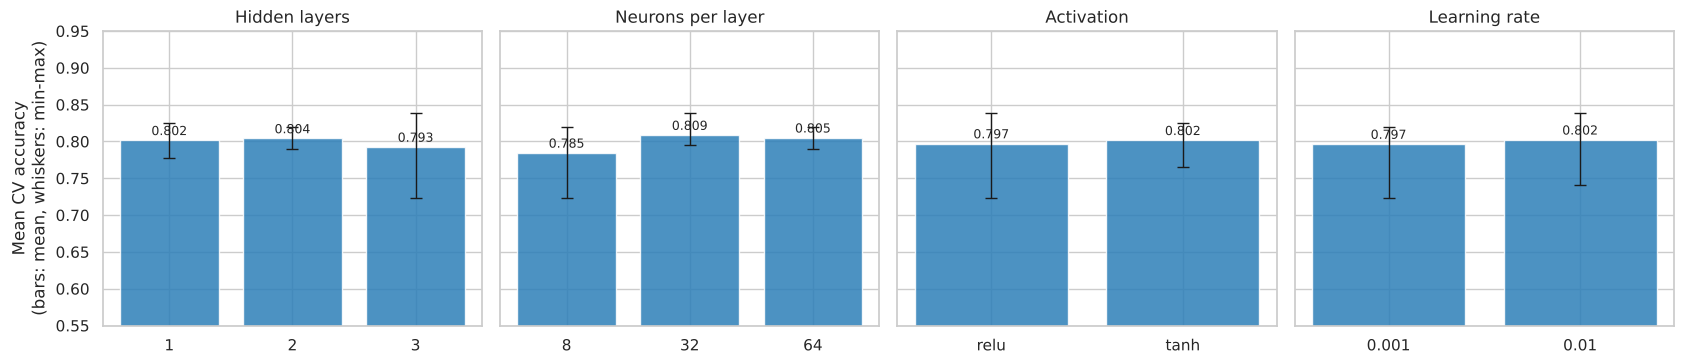

In [19]:
# Average CV accuracy for every value of every hyper-parameter (marginalising over the others)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
titles = {"n_hidden_layers": "Hidden layers", "n_neurons": "Neurons per layer",
          "activation": "Activation", "learning_rate": "Learning rate"}
for ax, p in zip(axes, param_grid):
    g = grid_results.groupby(p)["cv_acc"].agg(["mean", "min", "max"])
    ax.bar(g.index.astype(str), g["mean"], color="#2c7fb8", alpha=0.85)
    ax.errorbar(g.index.astype(str), g["mean"], yerr=[g["mean"]-g["min"], g["max"]-g["mean"]],
                fmt="none", ecolor="k", capsize=4, lw=1)
    for x, v in zip(g.index.astype(str), g["mean"]): ax.text(x, v+0.003, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(titles[p]); ax.set_ylim(0.55, 0.95)
axes[0].set_ylabel("Mean CV accuracy\n(bars: mean, whiskers: min-max)")
plt.tight_layout(); plt.show()

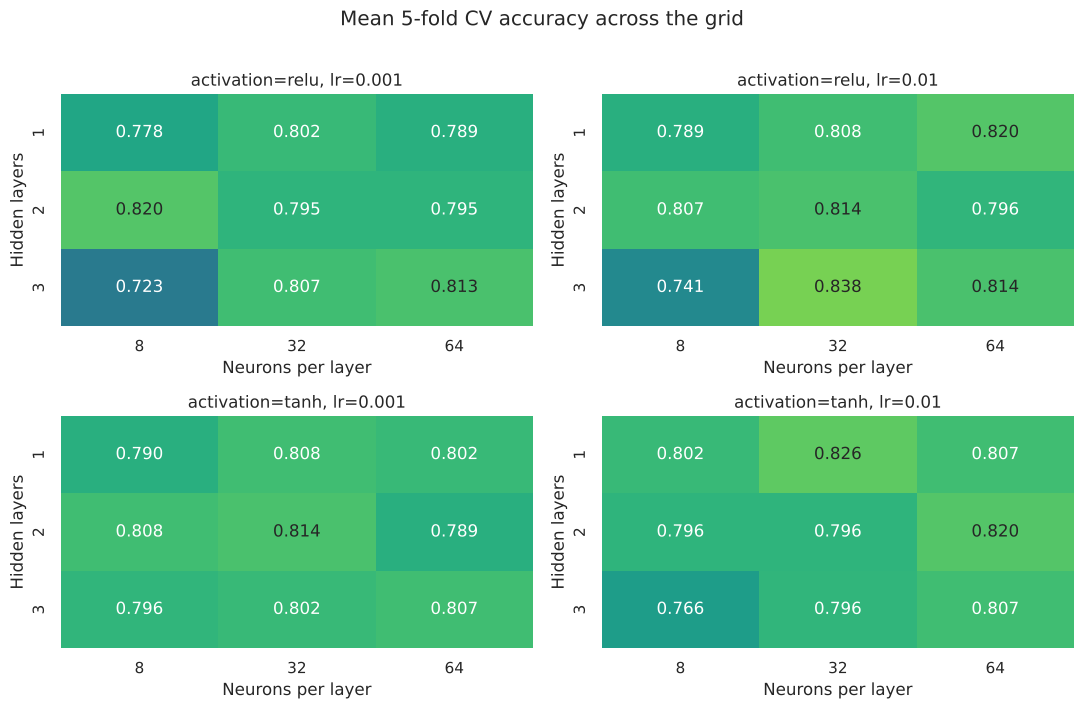

In [20]:
# Interaction view: architecture (layers x neurons) vs. activation / learning rate
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, ((act, lr), sub) in zip(axes.ravel(), grid_results.groupby(["activation", "learning_rate"])):
    pv = sub.pivot(index="n_hidden_layers", columns="n_neurons", values="cv_acc")
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="viridis", vmin=0.6, vmax=0.9, ax=ax, cbar=False)
    ax.set_title(f"activation={act}, lr={lr}"); ax.set_xlabel("Neurons per layer"); ax.set_ylabel("Hidden layers")
plt.suptitle("Mean 5-fold CV accuracy across the grid", y=1.01); plt.tight_layout(); plt.show()


**What the grid search shows**
- **The landscape is flat.** Averaged over the other settings, every hyper-parameter value gives a mean CV accuracy between 0.78 and 0.81; the best single configuration (3 layers × 32 ReLU neurons, lr = 0.01) reaches 0.838 and the worst (3 × 8 ReLU, lr = 0.001) 0.723.
- **Too few neurons hurts.** 8 neurons per layer is clearly the weakest width (mean 0.785), and the combination of 8 neurons with 3 layers is the worst region of the grid (0.72–0.77, except tanh/lr 0.001). 32 and 64 neurons perform similarly (0.809 / 0.805).
- **Depth, activation and learning rate have small average effects** (1–3 layers: 0.802 / 0.804 / 0.793; ReLU 0.797 vs. tanh 0.802; lr 0.001 vs. 0.01: 0.797 vs. 0.802). Their effect depends on the combination (see the heat-maps): e.g. the deepest network is the best configuration *and* is the most variable (largest min–max spread).
- **Caution:** the fold-to-fold standard deviation of accuracy is 0.04–0.10 – larger than the gap between the top-ranked configurations (0.838 vs. 0.826 vs. 0.820). The ranking among the top configurations is therefore **not statistically reliable**, and the best CV score is somewhat optimistic because it is the maximum over 36 noisy estimates.


### 4.4 Train the tuned model

The best configuration from the grid search is re-trained on the **entire training set** and evaluated once on the **test set**.

In [21]:
set_seed(); keras.backend.clear_session()
tuned = build_ann(X_train.shape[1], **best_params)
tuned.summary()
hist_tuned = tuned.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH, verbose=0)

p_tuned = tuned.predict(X_test, verbose=0).ravel()
yhat_tuned = (p_tuned >= 0.5).astype(int)
res_tuned = compute_metrics(y_test, yhat_tuned, p_tuned)
print("Tuned model test-set performance")
print(pd.Series(res_tuned).round(4).to_string())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

Tuned model test-set performance
Accuracy     0.9286
Precision    0.9130
Recall       0.9545
F1-score     0.9333
ROC-AUC      0.9750


## 5. Evaluation

### 5.1 Metrics: baseline vs. tuned model (test set)
Metrics use **Mine as the positive class**:
- **Accuracy** – share of all signals classified correctly.
- **Precision** – of the signals flagged as *mines*, how many really are mines (false alarms are costly but safe).
- **Recall** – of all real mines, how many were found (a miss is dangerous).
- **F1-score** – harmonic mean of precision and recall.

In [22]:
comparison = pd.DataFrame({"Baseline (default)": res_base, "Tuned (grid search)": res_tuned}).T
comparison["Δ vs baseline"] = ""
delta = (comparison.loc["Tuned (grid search)"].drop("Δ vs baseline").astype(float)
         - comparison.loc["Baseline (default)"].drop("Δ vs baseline").astype(float))
comparison.loc["Δ (tuned − baseline)"] = list(delta.round(4)) + [""]
comparison.drop(columns="Δ vs baseline").round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Baseline (default),0.9048,0.8462,1.0000,0.9167,0.9591
Tuned (grid search),0.9286,0.9130,0.9545,0.9333,0.9750
Δ (tuned − baseline),0.0238,0.0669,-0.0455,0.0167,0.0159


In [23]:
# Detailed per-class reports
names = ["Rock", "Mine"]
print("=== BASELINE ===");  print(classification_report(y_test, yhat_base,  target_names=names, digits=3))
print("=== TUNED ===");     print(classification_report(y_test, yhat_tuned, target_names=names, digits=3))

=== BASELINE ===
              precision    recall  f1-score   support

        Rock      1.000     0.800     0.889        20
        Mine      0.846     1.000     0.917        22

    accuracy                          0.905        42
   macro avg      0.923     0.900     0.903        42
weighted avg      0.919     0.905     0.903        42

=== TUNED ===
              precision    recall  f1-score   support

        Rock      0.947     0.900     0.923        20
        Mine      0.913     0.955     0.933        22

    accuracy                          0.929        42
   macro avg      0.930     0.927     0.928        42
weighted avg      0.929     0.929     0.928        42



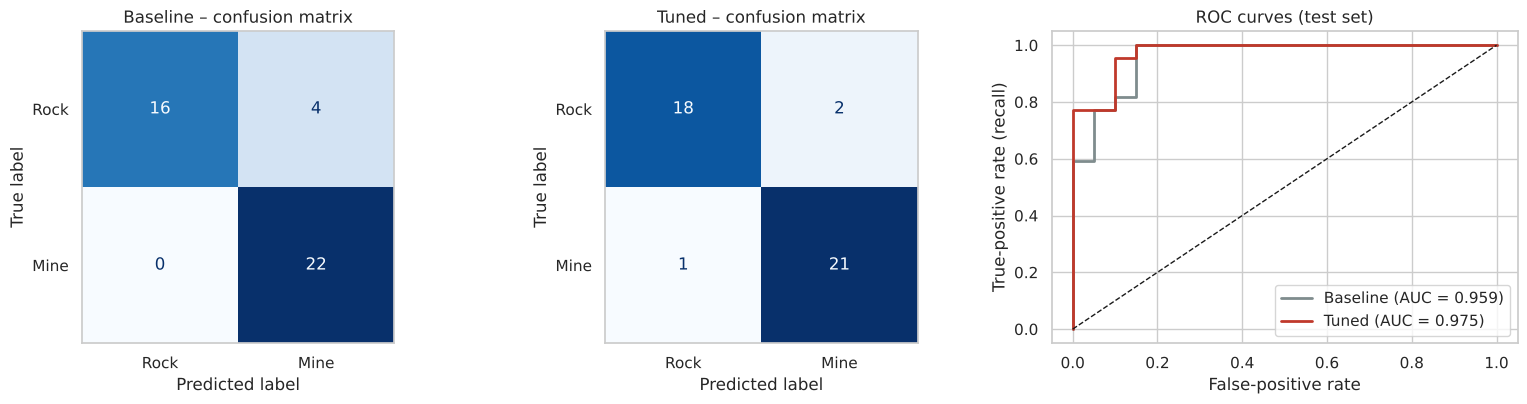

Tuned model -> missed mines (FN): 1, false alarms (FP): 2, correct mines (TP): 21, correct rocks (TN): 18
Baseline    -> missed mines (FN): 0, false alarms (FP): 4, correct mines (TP): 22, correct rocks (TN): 16


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (title, yh) in zip(axes[:2], [("Baseline", yhat_base), ("Tuned", yhat_tuned)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, yh), display_labels=names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title} – confusion matrix"); ax.grid(False)

for title, p, colr in [("Baseline", p_base, "#7f8c8d"), ("Tuned", p_tuned, "#c0392b")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[2].plot(fpr, tpr, color=colr, lw=2, label=f"{title} (AUC = {roc_auc_score(y_test, p):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1); axes[2].set_xlabel("False-positive rate"); axes[2].set_ylabel("True-positive rate (recall)")
axes[2].set_title("ROC curves (test set)"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, yhat_tuned).ravel()
print(f"Tuned model -> missed mines (FN): {fn}, false alarms (FP): {fp}, correct mines (TP): {tp}, correct rocks (TN): {tn}")
tn, fp, fn, tp = confusion_matrix(y_test, yhat_base).ravel()
print(f"Baseline    -> missed mines (FN): {fn}, false alarms (FP): {fp}, correct mines (TP): {tp}, correct rocks (TN): {tn}")

### 5.2 Robustness check: is the improvement real or just luck?
The test set contains only 42 signals, so one extra correct prediction changes accuracy by ≈ 2.4 points, and neural-network results also vary with the random weight initialisation. To judge whether tuning genuinely helps, we repeat the comparison on **10 random re-initialisations (seeds)** of both models (same train/test split, same hyper-parameters) and look at the mean ± standard deviation.

In [25]:
def repeated_eval(params, seeds=range(10)):
    rows = []
    for s in seeds:
        keras.backend.clear_session(); set_seed(100 + s)
        m = build_ann(X_train.shape[1], **params)
        m.fit(X_train, y_train, epochs=EPOCHS, batch_size=BATCH, verbose=0)
        p = m.predict(X_test, verbose=0).ravel()
        rows.append(compute_metrics(y_test, (p >= 0.5).astype(int), p))
    return pd.DataFrame(rows)

base_params = dict(n_hidden_layers=1, n_neurons=16, activation="relu", learning_rate=1e-3)
rep_base  = repeated_eval(base_params)
rep_tuned = repeated_eval(best_params)

summary = pd.concat({"Baseline": rep_base.agg(["mean", "std"]).T,
                     "Tuned":    rep_tuned.agg(["mean", "std"]).T}, axis=1).round(4)
summary

Baseline           Tuned        
              mean     std    mean     std
Accuracy    0.8929  0.0302  0.8929  0.0231
Precision   0.8829  0.0316  0.8696  0.0211
Recall      0.9182  0.0418  0.9364  0.0383
F1-score    0.8996  0.0285  0.9013  0.0223
ROC-AUC     0.9655  0.0168  0.9581  0.0195

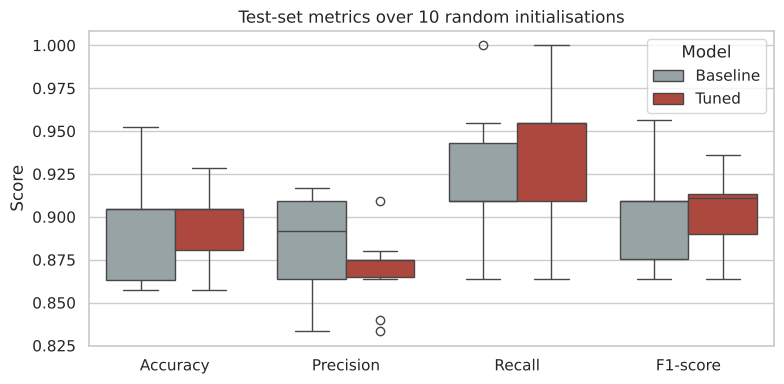

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_df = pd.concat([rep_base.assign(Model="Baseline"), rep_tuned.assign(Model="Tuned")]).melt(
    id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1-score"], var_name="Metric")
sns.boxplot(data=plot_df, x="Metric", y="value", hue="Model", palette=["#95a5a6", "#c0392b"], ax=ax)
ax.set_title("Test-set metrics over 10 random initialisations"); ax.set_ylabel("Score"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

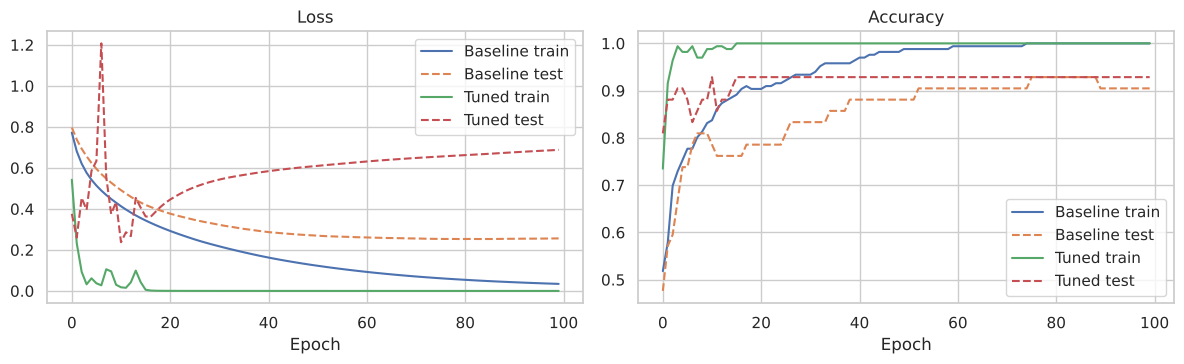

In [27]:
# Training-curve comparison: tuned vs baseline training loss (trained on the full training set)
set_seed(); keras.backend.clear_session()
h_b = build_ann(X_train.shape[1], **base_params).fit(X_train, y_train, validation_data=(X_test, y_test),
                                                      epochs=EPOCHS, batch_size=BATCH, verbose=0).history
set_seed(); keras.backend.clear_session()
h_t = build_ann(X_train.shape[1], **best_params).fit(X_train, y_train, validation_data=(X_test, y_test),
                                                      epochs=EPOCHS, batch_size=BATCH, verbose=0).history
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(h_b["loss"], label="Baseline train"); axes[0].plot(h_b["val_loss"], "--", label="Baseline test")
axes[0].plot(h_t["loss"], label="Tuned train");    axes[0].plot(h_t["val_loss"], "--", label="Tuned test")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(h_b["accuracy"], label="Baseline train"); axes[1].plot(h_b["val_accuracy"], "--", label="Baseline test")
axes[1].plot(h_t["accuracy"], label="Tuned train");    axes[1].plot(h_t["val_accuracy"], "--", label="Tuned test")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()


## 6. Discussion & Conclusions

### 6.1 Baseline vs. tuned model

| Test set (42 signals) | Accuracy | Precision | Recall | F1 | Missed mines | False alarms |
|---|---|---|---|---|---|---|
| Baseline (1 × 16 ReLU, lr 0.001) – seed 42 | 0.905 | 0.846 | 1.000 | 0.917 | 0 | 4 |
| Tuned (3 × 32 ReLU, lr 0.01) – seed 42 | 0.929 | 0.913 | 0.955 | 0.933 | 1 | 2 |
| Baseline – mean ± std over 10 seeds | 0.893 ± 0.030 | 0.883 ± 0.032 | 0.918 ± 0.042 | 0.900 ± 0.029 | | |
| Tuned – mean ± std over 10 seeds | 0.893 ± 0.023 | 0.870 ± 0.021 | 0.936 ± 0.038 | 0.901 ± 0.022 | | |

**Single run.** With the primary seed the tuned model looks better: accuracy +2.4 points (one extra correct signal), precision +6.7 points (fewer false alarms: 2 instead of 4) and F1 +1.7 points, at the price of recall falling from 1.00 to 0.95 (it missed one mine, which the baseline did not). ROC-AUC also improves slightly (0.959 → 0.975).

**Robustness check.** When the models are re-trained with 10 different random initialisations, the picture changes: mean accuracy is identical (0.893 for both) and the F1-scores are practically equal (0.900 vs. 0.901). The tuned model has slightly higher recall (0.936 vs. 0.918) and lower run-to-run variability in accuracy, but slightly lower precision and ROC-AUC. All differences are well inside one standard deviation. **We therefore cannot claim that hyper-parameter tuning produced a statistically meaningful improvement on this data set**; the +2.4 point gain from the single run is mostly seed/test-split noise (with 42 test samples, one signal = 2.4 points).

### 6.2 Effects of the hyper-parameters
- **Network width** was the clearest factor: very narrow layers (8 neurons) under-perform, especially when stacked into 3 layers, whereas 32–64 neurons are consistently better.
- **Depth, activation function and learning rate** changed average CV accuracy by only ≈ 0.01. A higher learning rate (0.01) with ReLU worked best for the larger networks, because with a fixed budget of 100 epochs it converges quickly; the lower rate is not worse on average.
- **Over-fitting is the dominant issue, not under-fitting.** Both models reach 100 % training accuracy; the tuned model does so within ≈ 15 epochs, and its test loss (a diagnostic only, never used for selection) rises after ≈ 15 epochs even though test accuracy stays stable – the network becomes over-confident. The baseline shows the same pattern more slowly. Tuning architecture and learning rate alone cannot remove this; regularisation or early stopping would be needed.

### 6.3 Business interpretation
Both models detect ≈ 90 % of signals correctly and have recall for mines of ≈ 92–94 % on average (≈ 5–8 % of mines missed). For a safety-critical application this miss rate is still too high to rely on the model alone; it would be suitable as a decision-support / screening tool, with the decision threshold lowered (trading precision for recall) if missing a mine is judged much worse than a false alarm.

### 6.4 Limitations and possible improvements
- **Very small data set** (208 samples; 42 in the test set): metrics have wide uncertainty, and the grid-search ranking is noisy (CV std 0.04–0.10).
- **Aspect-angle information is not available**, so a purely random split may place similar-angle signals in train and test sets (the original study by Gorman & Sejnowski also noted uneven performance for this reason).
- Only four hyper-parameters were searched, with a fixed optimiser, batch size and number of epochs.
- **Ideas not implemented here:** early stopping, dropout / L2 weight decay, searching those regularisation settings, repeated stratified CV for a more reliable ranking, decision-threshold tuning for mine recall, and comparison with non-neural baselines (e.g. SVM, random forest).

### 6.5 Conclusion
A standardised ANN trained on the 60 sonar frequency bands separates mines from rocks with about **90 % test accuracy**. A systematic grid search (36 configurations, 5-fold CV) showed that network width matters most and that most other settings are roughly interchangeable. The best configuration scored higher than the baseline on the main test split, but repeated runs show **no reliable difference in accuracy or F1** between the baseline and the tuned model – on a data set this small, over-fitting and evaluation noise outweigh the benefit of hyper-parameter tuning, and regularisation is the more promising next step.
